# Midterm — обученная baseline-модель поиска по кодексам РК

**Проект:** lawrag — офлайн-поиск норм по Конституции и кодексам Республики Казахстан (RU + KK).
Продолжение Assignment 2 (подготовка данных и лексический baseline TF-IDF).

Ноутбук выполняется `Restart → Run All` без правки путей: корень репозитория находится автоматически, все параметры —
в `midterm/config.py`. Обученная модель и эмбеддинги корпуса кэшируются: первый прогон на ноутбуке (Apple M1 Pro, MPS)
— порядка 30–75 минут, повторный — несколько минут. `FORCE_TRAIN = True` переобучает модель с нуля.

| № | Критерий midterm | Раздел |
|---|---|---|
| 1 | работающий код | весь ноутбук + пакет `midterm/` |
| 2 | обученная baseline-модель (конфигурация, параметры обучения) | §5 |
| 3 | минимум 2 метрики с объяснением | §3 |
| 4 | первые результаты: таблица + график + интерпретация | §6, §7 |
| 5 | обоснование выбора модели и альтернативы | §2 |
| 6 | презентация | `slides/` |
| 7 | исследовательский вывод | §8 |

## 0. Окружение

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "midterm" / "config.py").exists()
                    or (p / "notebooks" / "midterm" / "midterm" / "config.py").exists())
if not (NOTEBOOK_DIR / "midterm" / "config.py").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "notebooks" / "midterm"
sys.path.insert(0, str(NOTEBOOK_DIR))

from midterm import data as D, experiment as E, retrieval as R, train as T
from midterm.config import default_settings

FORCE_TRAIN = False
SETTINGS = default_settings(NOTEBOOK_DIR)
DEVICE = T.pick_device()
SETTINGS.paths.outputs.mkdir(parents=True, exist_ok=True)
COLORS = {E.TFIDF: "#9a9893", E.PRETRAINED: "#2a78d6", E.FINETUNED: "#eb6834"}
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print("repo:", SETTINGS.paths.root, "| device:", DEVICE)

repo: /Users/baltabaev/PycharmProjects/lawrag | device: mps


## 1. Задача и данные

**Задача** — информационный поиск: по запросу на русском или казахском найти статью кодекса, в которой содержится ответ.
Модель ранжирует все 43 857 фрагментов (chunks) обоих языков; ответ засчитывается, если в выдаче есть любой фрагмент
целевой статьи на целевом языке.

**Данные** — пары *(запрос → статья)*, добытые из самого корпуса (Assignment 2, §3.3): заголовок → статья (`heading`),
предложение со ссылкой с вырезанным номером → статья-адресат (`xref`), термин → статья с определением (`definition`),
текст на одном языке → та же статья на другом (`xlang`). Очистка и разбиение воспроизводят Assignment 2 один в один:
`StratifiedGroupKFold` по статьям (группа — статья, страта — тип пары), 80/10/10. Ни одна статья validation/test
не встречается в train — модель проверяется на ранее не использованных данных.

In [2]:
chunks, pairs = D.load(SETTINGS)
INDEX = R.Index(chunks)
SPLITS = {name: D.split(pairs, name) for name in D.SPLITS}

overview = pd.DataFrame({name: {"пар": len(df), "статей": df.target_article.nunique(),
                                **df.kind.value_counts().reindex(D.KIND_ORDER).to_dict()}
                         for name, df in SPLITS.items()}).T
overlap = {(a, b): len(set(SPLITS[a].target_article) & set(SPLITS[b].target_article))
           for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))}
print(f"Индекс: {len(chunks):,} фрагментов ({chunks.lang.value_counts().to_dict()})")
print("Пересечение статей между выборками:", overlap)
overview

Индекс: 43,857 фрагментов ({'ru': 22361, 'kk': 21496})
Пересечение статей между выборками: {('train', 'validation'): 0, ('train', 'test'): 0, ('validation', 'test'): 0}


,пар,статей,heading,xref,definition,xlang
train,23842,6005,6400,8935,2107,6400
validation,3069,740,800,1116,353,800
test,3246,740,800,1116,530,800


## 2. Обоснование выбора модели

**Выбранная модель — bi-encoder `intfloat/multilingual-e5-small`, дообученный контрастивно на train-парах.**

Какие свойства данных определили выбор:

| Свойство данных (из EDA Assignment 2) | Следствие для модели |
|---|---|
| Target — одна из ~17 000 статей, и новые статьи появляются с каждой поправкой | классификатор с фиксированным набором меток не подходит; нужна модель *сходства* запрос↔текст, которая работает для статей, не виденных при обучении |
| Два языка, у RU и KK текста почти нет общих слов (TF-IDF на xlang ≈ 0) | нужна многоязычная модель с общим векторным пространством; e5 обучена на 100 языках, включая казахский (словарь XLM-R) |
| Запросы xref/definition лексически похожи на *многие* статьи (TF-IDF recall@1 ≈ 0.02) | нужна модель, обучаемая отличать «определяющую» статью от «упоминающей» — контрастивное обучение с hard negatives именно это и делает |
| ~24 тыс. обучающих пар, офлайн-эксплуатация, ноутбук без дискретной GPU | маленькая модель (118 M параметров, вектор 384) обучается за минуты–десятки минут и кодирует индекс без GPU |
| Тот же класс модели используется в production-ветке проекта (dense retrieval) | результат напрямую переносится в систему: меняется только чекпойнт эмбеддера |

**Альтернативы и почему они пока не выбраны:**

| Альтернатива | Почему не сейчас |
|---|---|
| TF-IDF / BM25 | не обучается на парах и не решает межъязыковой поиск; оставлен как нижняя граница (§4) |
| Классификатор «запрос → статья» (логрегрессия / fine-tuned BERT с softmax по статьям) | 17 тыс. классов при ~4 примерах на класс; статьи test-выборки по построению не встречаются в train, классификатор их предсказать не может |
| `BAAI/bge-m3` (568 M) — эмбеддер production-конфигурации | в 5 раз больше; дообучение на MPS займёт часы, кодирование индекса ~1 ч. Это следующий шаг, когда baseline-протокол отлажен на малой модели |
| Cross-encoder (`bge-reranker-v2-m3`) | переранжирует top-k, но не ищет по всему индексу (44 тыс. пар на запрос); это второй каскад поверх bi-encoder, а не baseline |
| LLM-эмбеддинги через API (Gemini) | нарушают требование офлайн-работы на пути запроса; используются в проекте только как внешняя точка сравнения |

## 3. Метрики

| Метрика | Что показывает | Почему подходит |
|---|---|---|
| **recall@1** | доля запросов, где правильная статья — первая в выдаче | система цитирует верхний результат; ошибка на первом месте = неверная норма в ответе |
| **recall@10** | доля запросов, где правильная статья есть в топ-10 | в RAG в контекст LLM попадают ~10 фрагментов; если статьи нет в топ-10, её не спасёт ни переранжирование, ни генерация |
| **MRR@10** | среднее 1/ранг правильной статьи (0, если её нет в топ-10) | одно число, чувствительное к *позиции*: отличает «на 2-м месте» от «на 9-м», чего не видит recall@10 |

Accuracy/F1 не применимы: это не классификация с фиксированными метками, а ранжирование тысяч кандидатов.
Метрики считаются отдельно по типам запросов и языкам — общее число маскирует слабость на xref/definition (Assignment 2).
Для разности моделей приводится 95 % бутстрэп-интервал.

**Изменение протокола относительно Assignment 2.** Межъязыковой запрос ранжируется только среди фрагментов целевого
языка: иначе его собственный «двойник» на исходном языке всегда на первом месте и recall@1 структурно равен нулю.
Индексируется `embed_text` (иерархия + заголовок + текст) — то, что индексирует production. Поэтому числа TF-IDF
ниже не совпадают с Assignment 2 один в один.

### Гипотеза до запуска (ожидаемые значения, test)

Оценка составлена *до* обучения по результатам Assignment 2 и опубликованным результатам e5 на многоязычном поиске.
Это гипотеза, а не результат; фактические значения — в §6.

| Система | recall@1 | recall@10 | MRR@10 |
|---|---|---|---|
| TF-IDF | ~0.20 | ~0.45 | ~0.27 |
| e5-small, pretrained | ~0.25–0.30 | ~0.55–0.60 | ~0.35 |
| e5-small, fine-tuned | ~0.35–0.45 | ~0.70–0.75 | ~0.45–0.50 |

Главные ожидания: (H1) дообучение даёт наибольший прирост на `xref` и `definition`; (H2) `xlang` уже у
pretrained-модели существенно выше нуля благодаря многоязычному предобучению; (H3) разница RU/KK остаётся малой.

## 4. Модели без обучения: TF-IDF и pretrained e5

In [3]:
RESULTS = {"validation": {}, "test": {}}
tfidf = E.tfidf_system(INDEX, SETTINGS)
pretrained_model = T.load_model(SETTINGS.train.base_model, SETTINGS.train, DEVICE)
pretrained, pretrained_emb = E.dense_system(E.PRETRAINED, pretrained_model, "e5-small-pretrained", INDEX, SETTINGS)
for system in (tfidf, pretrained):
    for name in RESULTS:
        RESULTS[name][system.name] = E.score(system, INDEX, SPLITS[name], SETTINGS)
E.summary_table(RESULTS["validation"], SPLITS["validation"]).round(3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

TF-IDF                           e5-small (pretrained)           \
                n recall@1 recall@10 MRR@10                     n recall@1   
all          3069    0.288     0.514  0.352                  3069    0.426   
heading       800    0.905     0.989  0.936                   800    0.875   
xref         1116    0.037     0.392  0.141                  1116    0.080   
definition    353    0.023     0.283  0.079                   353    0.017   
xlang         800    0.138     0.312  0.183                   800    0.639   
lang=ru      1530    0.297     0.525  0.361                  1530    0.461   
lang=kk      1539    0.278     0.504  0.343                  1539    0.390   

                             
           recall@10 MRR@10  
all            0.616  0.485  
heading        0.994  0.925  
xref           0.349  0.159  
definition     0.096  0.035  
xlang          0.839  0.700  
lang=ru        0.642  0.516  
lang=kk        0.589  0.454

## 5. Обучение baseline-модели

**Метод.** Контрастное обучение (`MultipleNegativesRankingLoss`): для запроса правильный фрагмент должен получить
косинус выше, чем все остальные фрагменты батча (in-batch negatives) и один *hard negative* — лучший по
pretrained-модели фрагмент *другой* статьи. Hard negatives берутся только из статей, не входящих в validation/test.
`NO_DUPLICATES`-сэмплер не кладёт в один батч одинаковые тексты (иначе пары-определения одной статьи стали бы
ложными негативами друг для друга).

In [4]:
from dataclasses import asdict

pd.Series(asdict(SETTINGS.train), name="значение").to_frame()

,значение
base_model,intfloat/multilingual-e5-small
query_prefix,query:
passage_prefix,passage:
max_seq_length,256
epochs,1
batch_size,64
mini_batch_size,16
learning_rate,0.00003
warmup_ratio,0.1
weight_decay,0.01


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Параметров: 118 M | train-пар: 23,842 | устройство: mps | время обучения: 43.4 мин


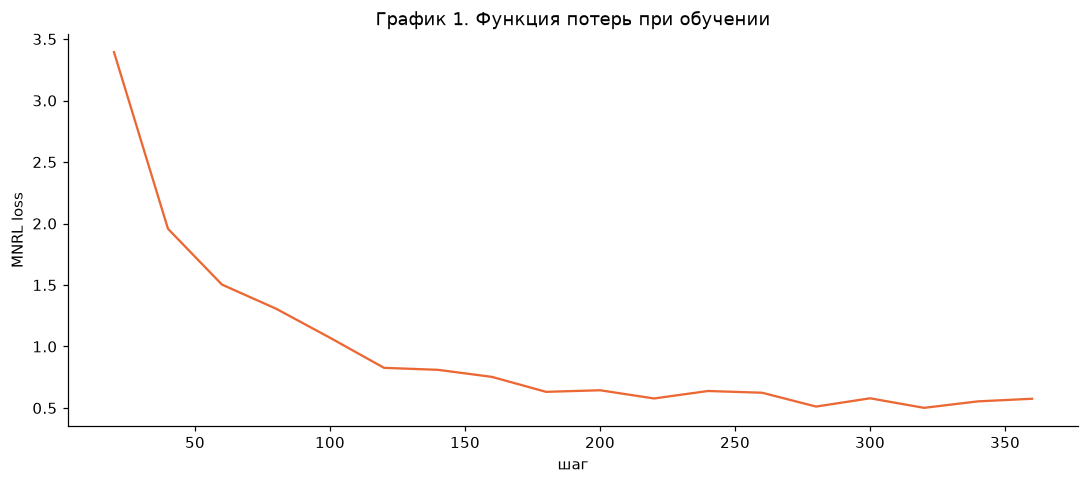

In [5]:
finetuned_model, TRAIN_META = E.train_or_load(pretrained_model, pretrained_emb, INDEX, pairs, SETTINGS, DEVICE,
                                              force=FORCE_TRAIN)
n_params = sum(p.numel() for p in finetuned_model.parameters())
print(f"Параметров: {n_params / 1e6:.0f} M | train-пар: {TRAIN_META['train_pairs']:,} | "
      f"устройство: {TRAIN_META['device']} | время обучения: {TRAIN_META['train_seconds'] / 60:.1f} мин")

loss = pd.DataFrame(TRAIN_META["loss_log"])
fig, ax = plt.subplots()
ax.plot(loss["step"], loss["loss"], color=COLORS[E.FINETUNED])
ax.set_xlabel("шаг")
ax.set_ylabel("MNRL loss")
ax.set_title("График 1. Функция потерь при обучении")
plt.tight_layout()
plt.show()

In [6]:
finetuned, _ = E.dense_system(E.FINETUNED, finetuned_model, "e5-small-ft-" + TRAIN_META["trained_at"].replace(":", ""), INDEX,
                              SETTINGS)
for name in RESULTS:
    RESULTS[name][E.FINETUNED] = E.score(finetuned, INDEX, SPLITS[name], SETTINGS)
print("Validation:")
E.summary_table(RESULTS["validation"], SPLITS["validation"]).round(3)

Validation:


TF-IDF                           e5-small (pretrained)           \
                n recall@1 recall@10 MRR@10                     n recall@1   
all          3069    0.288     0.514  0.352                  3069    0.426   
heading       800    0.905     0.989  0.936                   800    0.875   
xref         1116    0.037     0.392  0.141                  1116    0.080   
definition    353    0.023     0.283  0.079                   353    0.017   
xlang         800    0.138     0.312  0.183                   800    0.639   
lang=ru      1530    0.297     0.525  0.361                  1530    0.461   
lang=kk      1539    0.278     0.504  0.343                  1539    0.390   

                            e5-small (fine-tuned)                            
           recall@10 MRR@10                     n recall@1 recall@10 MRR@10  
all            0.616  0.485                  3069    0.555     0.777  0.624  
heading        0.994  0.925                   800    0.950     0.999  0.972  
xref           0.349  0.159                  1116    0.151     0.486  0.246  
definition     0.096  0.035                   353    0.499     0.810  0.589  
xlang          0.839  0.700                   800    0.746     0.949  0.819  
lang=ru        0.642  0.516                  1530    0.586     0.799  0.654  
lang=kk        0.589  0.454                  1539    0.524     0.756  0.594

## 6. Результаты на test

Test оценивается один раз, после того как все решения приняты на validation.

In [7]:
test_table = E.summary_table(RESULTS["test"], SPLITS["test"])
test_table.to_csv(SETTINGS.paths.outputs / "test_metrics.csv")
test_table.round(3)

TF-IDF                           e5-small (pretrained)           \
                n recall@1 recall@10 MRR@10                     n recall@1   
all          3246    0.259     0.505  0.329                  3246    0.398   
heading       800    0.879     0.986  0.920                   800    0.880   
xref         1116    0.034     0.440  0.151                  1116    0.085   
definition    530    0.028     0.296  0.088                   530    0.032   
xlang         800    0.105     0.254  0.147                   800    0.596   
lang=ru      1583    0.259     0.497  0.328                  1583    0.416   
lang=kk      1663    0.259     0.513  0.330                  1663    0.381   

                            e5-small (fine-tuned)                            
           recall@10 MRR@10                     n recall@1 recall@10 MRR@10  
all            0.591  0.459                  3246    0.577     0.797  0.647  
heading        0.990  0.925                   800    0.948     0.996  0.968  
xref           0.347  0.161                  1116    0.182     0.489  0.270  
definition     0.164  0.066                   530    0.675     0.934  0.756  
xlang          0.816  0.670                   800    0.692     0.935  0.779  
lang=ru        0.611  0.476                  1583    0.601     0.798  0.663  
lang=kk        0.572  0.443                  1663    0.554     0.795  0.631

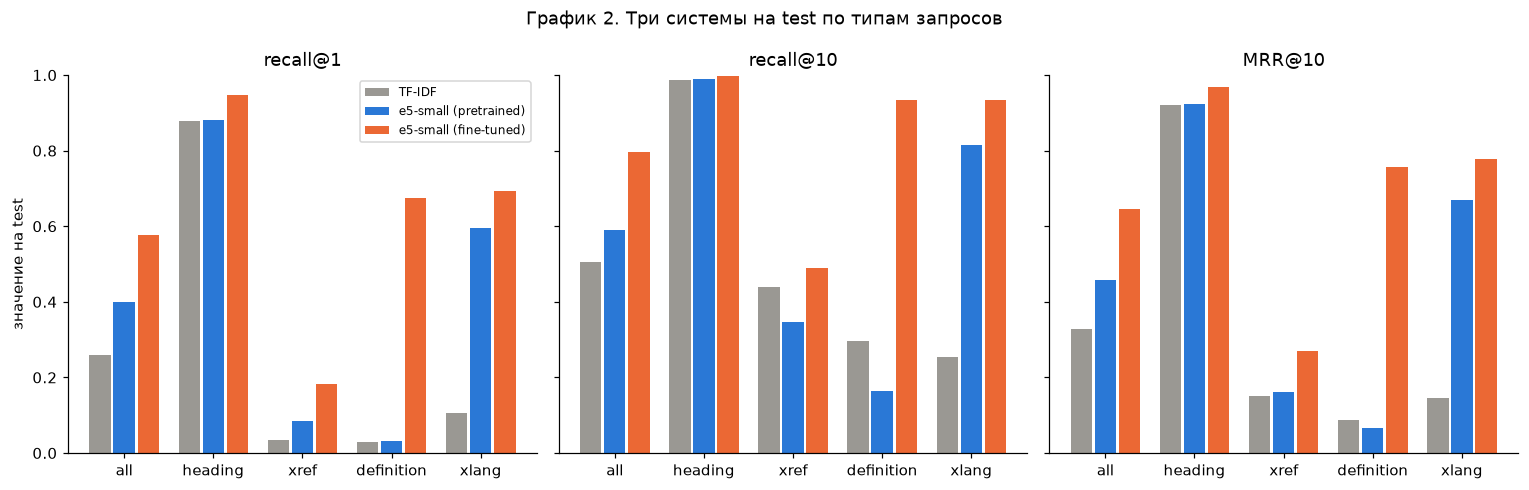

In [8]:
fig, axes = plt.subplots(1, len(R.METRICS), figsize=(14, 4.5), sharey=True)
rows = ["all", *D.KIND_ORDER]
x = np.arange(len(rows))
width = 0.27
for ax, metric in zip(axes, R.METRICS):
    for i, system in enumerate(RESULTS["test"]):
        values = test_table[system].loc[rows, metric]
        ax.bar(x + (i - 1) * width, values, width=width - 0.03, color=COLORS[system], label=system)
    ax.set_xticks(x, rows)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("значение на test")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("График 2. Три системы на test по типам запросов")
plt.tight_layout()
plt.savefig(SETTINGS.paths.outputs / "test_by_kind.png", bbox_inches="tight")
plt.show()

In [9]:
def diff_ci(a: np.ndarray, b: np.ndarray, metric: str, n_boot: int = 1000, seed: int = 13):
    rng = np.random.default_rng(seed)
    idx = [rng.integers(0, len(a), len(a)) for _ in range(n_boot)]
    d = [R.metrics(b[i])[metric] - R.metrics(a[i])[metric] for i in idx]
    return np.quantile(d, [0.025, 0.975])


comparisons = [(E.TFIDF, E.FINETUNED), (E.PRETRAINED, E.FINETUNED)]
pd.DataFrame({f"{b} − {a}": {m: "{:+.3f} [{:+.3f}; {:+.3f}]".format(
    R.metrics(RESULTS['test'][b])[m] - R.metrics(RESULTS['test'][a])[m],
    *diff_ci(RESULTS["test"][a], RESULTS["test"][b], m)) for m in R.METRICS}
    for a, b in comparisons}).T

,recall@1,recall@10,MRR@10
e5-small (fine-tuned) − TF-IDF,+0.318 [+0.301; +0.335],+0.291 [+0.272; +0.311],+0.318 [+0.302; +0.334]
e5-small (fine-tuned) − e5-small (pretrained),+0.179 [+0.161; +0.196],+0.205 [+0.189; +0.221],+0.188 [+0.174; +0.202]


## 7. Где модель ошибается

Разбираем ошибки fine-tuned модели на test: (1) в каком кодексе оказывается неверный топ-1 — в том же или в чужом;
(2) примеры запросов, где правильной статьи нет в топ-10.

In [10]:
test = SPLITS["test"].copy()
test["rank"] = RESULTS["test"][E.FINETUNED]
test["top1_article"] = R.top1_articles(INDEX, test, finetuned.score, SETTINGS.eval)
wrong = test[test["rank"] != 1].copy()
wrong["same_code"] = wrong["top1_article"].str.split("/").str[0] == wrong["target_article"].str.split("/").str[0]
error_types = wrong.groupby("kind").agg(ошибок_top1=("rank", "size"), в_том_же_кодексе=("same_code", "mean"),
                                         нет_в_топ10=("rank", lambda r: (r == 0).mean()))
error_types.reindex(D.KIND_ORDER).round(2)

,ошибок_top1,в_том_же_кодексе,нет_в_топ10
kind,,,
heading,42,0.67,0.07
xref,913,0.71,0.62
definition,172,0.02,0.20
xlang,246,0.67,0.21


In [11]:
pd.set_option("display.max_colwidth", 120)
wrong[wrong["rank"] == 0].groupby("kind").head(2)[["kind", "lang", "query", "target_article", "top1_article"]]

,kind,lang,query,target_article,top1_article
250,heading,ru,Налоговый период и налоговая отчетность,nk2017/st710,nk2017/st314
337,heading,kk,"Кедендік баждарды, салықтарды төлеу жөніндегі міндеттің орындалуын қамтамасыз ету ретінде енгізілген аванстық төлемд...",tamk/st113,tamk/st141
801,xref,ru,Учреждение не вправе самостоятельно отчуждать или иным способом распоряжаться закрепленным за ним имуществом и имуще...,gk/st161,gk/st200
806,xref,ru,Продление срока действия договора производится по правилам настоящего Кодекса.,gk/st397,gk/st405
1960,xlang,ru,пункт 4. Таможенному декларированию подлежит ввезенное на таможенную территорию Евразийского экономического союза ил...,tamk/st374,tamk/st375
1987,xlang,ru,"пункт 3. Таможенный орган назначения не позднее трех часов с момента получения сведений, указанных в подпункте 2) пу...",tamk/st539,tamk/st303
2740,definition,ru,кормилец,sk/st1,appk/st4
2741,definition,ru,что означает термин «кормилец»?,sk/st1,lk/st4


### Интерпретация

**Итог на test (3 246 запросов, 740 статей, не виденных при обучении):**

| Система | recall@1 | recall@10 | MRR@10 |
|---|---|---|---|
| TF-IDF | 0.259 | 0.505 | 0.329 |
| e5-small, pretrained | 0.398 | 0.591 | 0.459 |
| **e5-small, fine-tuned** | **0.577** | **0.797** | **0.647** |

Прирост дообучения над pretrained: recall@1 +0.179 [+0.161; +0.196], recall@10 +0.205, MRR@10 +0.188
[+0.174; +0.202] (95 % бутстрэп, таблица выше). Над TF-IDF: MRR@10 +0.318 [+0.302; +0.334]. Интервалы не содержат
нуля — улучшение не случайно. Фактические значения лучше гипотезы до запуска (§3): ожидали MRR@10 ≈ 0.45–0.50,
получили 0.647.

Ниже — автоматическая проверка гипотез по этим числам.

In [12]:
t = test_table
gain = (t[E.FINETUNED] - t[E.PRETRAINED])["MRR@10"].loc[list(D.KIND_ORDER)].sort_values(ascending=False)
print("Прирост MRR@10 от дообучения по типам запросов:", gain.round(3).to_dict())
print("H1 (наибольший прирост на xref/definition):", set(gain.index[:2]) == {"xref", "definition"})
print("H2 (xlang pretrained recall@10 > 0.3):", t[E.PRETRAINED].loc["xlang", "recall@10"] > 0.3)
ru_kk = abs(t[E.FINETUNED].loc["lang=ru", "MRR@10"] - t[E.FINETUNED].loc["lang=kk", "MRR@10"])
print(f"H3 (|RU − KK| MRR@10 < 0.03): {ru_kk < 0.03} (разница {ru_kk:.3f})")

Прирост MRR@10 от дообучения по типам запросов: {'definition': 0.69, 'xlang': 0.109, 'xref': 0.109, 'heading': 0.043}
H1 (наибольший прирост на xref/definition): False
H2 (xlang pretrained recall@10 > 0.3): True
H3 (|RU − KK| MRR@10 < 0.03): False (разница 0.031)


**Что получилось хорошо.**

* **Определения** — главный эффект дообучения: recall@1 0.03 → 0.68, recall@10 0.16 → 0.93. Pretrained-модель и TF-IDF
  находят статьи, где термин *встречается*; дообученная научилась находить статью, где он *определён*
  («Основные понятия…»). Осторожно: определения сосредоточены в немногих статьях, и модель могла выучить шаблон
  «вопрос-определение → статья с понятиями кодекса»; в test эти статьи новые, но сам шаблон тот же.
* **Межъязыковой поиск** — уже у pretrained-модели recall@10 0.82 (TF-IDF 0.25): многоязычное предобучение работает
  для казахского. Дообучение добавляет ещё +0.12 recall@10.
* **Заголовки** решены всеми системами (recall@10 ≈ 0.99) — эта категория не различает модели.

**Где модель ошибается.**

* **xref — главная слабость:** recall@1 0.18, recall@10 0.49. Это ближе всего к реальным вопросам («по правилам
  настоящего Кодекса…»). 71 % неверных top-1 — в *том же* кодексе, а в 62 % случаев правильной статьи нет в топ-10.
  Часто предложение-ссылка просто не содержит сведений о предмете целевой статьи (пример: «Продление срока действия
  договора производится по правилам настоящего Кодекса» → ст. 397 ГК): по тексту запроса её нельзя однозначно
  определить, и это частично ограничение самих данных, а не модели.
* **Соседние статьи:** в ошибках heading и xlang ~67 % — тот же кодекс (таможенный: ст. 374 против 375). Это задача
  переранжирования (cross-encoder), а не первого этапа поиска.
* **Казахский язык** уступает русскому: MRR@10 0.631 против 0.663 (разница 0.031, у pretrained — 0.033).
  Разрыв небольшой, но устойчивый — H3 формально не подтвердилась.

**Насколько результат приемлем.** recall@10 0.80 в целом — для RAG это значит, что в 4 из 5 случаев нужная статья
попадает в контекст LLM. Для заголовков, определений и межъязыковых запросов (≥ 0.93) этого достаточно; для xref
(0.49) — нет, порог следующего этапа (≥ 0.8 на xref) не достигнут.

**Что улучшить.** (1) Гибридный поиск: на xref TF-IDF даёт recall@10 0.44 — сигнал, частично дополняющий
dense-модель; объединение через RRF уже реализовано в конвейере проекта. (2) Переранжирование top-20
cross-encoder’ом против ошибок «соседняя статья». (3) Больше эпох / подбор learning rate на validation —
обучена одна эпоха без подбора. (4) bge-m3 (568 M) вместо e5-small.

## 8. Исследовательский вывод

1. **Что показал эксперимент.** Одна эпоха контрастного дообучения на 23 842 синтетических парах подняла MRR@10
   небольшой многоязычной модели с 0.459 до 0.647 на статьях, не виденных при обучении (+0.188, 95 % ДИ
   [+0.174; +0.202]); относительно лексического baseline — с 0.329 до 0.647. Вклад архитектуры (dense vs TF-IDF)
   сосредоточен в межъязыковом поиске, вклад дообучения — в определениях и, меньше, в ссылках.
2. **Ограничения.** (а) Запросы синтетические — получены из самого корпуса; на реальных вопросах числа будут другими.
   (б) Одна эпоха, гиперпараметры не подбирались. (в) Оценивается только dense-ветка без лексики, порога
   релевантности и переранжирования. (г) Определения сконцентрированы в немногих статьях — их метрика оптимистична.
   (д) Даты редакций в рабочей БД не импортированы (все 1900-01-01) — поиск «на дату» в этом эксперименте не проверяется.
3. **Следующий эксперимент.** Внешний test из 100–200 реальных вопросов с разметкой юриста (RU + KK); на нём —
   fine-tuned e5-small против гибрида RRF (dense + лексика + ссылки) с переранжированием и против bge-m3. Основной
   вопрос: переносится ли прирост на синтетике на реальные вопросы, и закрывает ли гибрид провал на xref-запросах.